## Setup

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'src').exists():
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / 'src').exists():
    raise RuntimeError('Start Jupyter from the repository root or the notebooks directory.')
sys.path.insert(0, str(REPO_ROOT / 'src'))
from common import load_data, validate_data, EXPRESSION_FEATURE_PATH
from correlations import participant_correlations
import manuscript_figures as mf
mf.set_house_style()

# ---- public release data (shared by every figure below) ----
DIMENSIONS = ['Artificiality', 'Trustworthiness', 'Attractiveness']
trials = load_data()
validate_data(trials)
face_means = trials.groupby('stimulus_id')[DIMENSIONS].mean()
face_means = face_means.join(trials.groupby('stimulus_id').size().rename('n_ratings'))
corr, partial = participant_correlations(trials)
features = pd.read_csv(EXPRESSION_FEATURE_PATH)

manifest = pd.read_csv(REPO_ROOT / 'data' / 'metadata' / 'stimulus_manifest.csv')
FILENAME = manifest.set_index('stimulus_id')['generated_filename']
IMAGE_DIR = REPO_ROOT / 'stimuli' / 'images'
def find_image(stimulus_id):
    fn = FILENAME.get(stimulus_id)
    if fn is None:
        return None
    path = IMAGE_DIR / fn
    return str(path) if path.exists() else None

print(f"{len(trials):,} ratings | {trials['participant_id'].nunique()} participants | "
      f"{trials['stimulus_id'].nunique()} stimuli | figures drawn by src/manuscript_figures.py")

50,000 ratings | 100 participants | 500 stimuli | figures drawn by src/manuscript_figures.py


## Example faces per rating dimension

For each dimension (artificiality, trustworthiness, attractiveness), the five lowest- and five highest-rated faces by per-face mean, ordered low-to-high within each group, with the mean rating below each face.

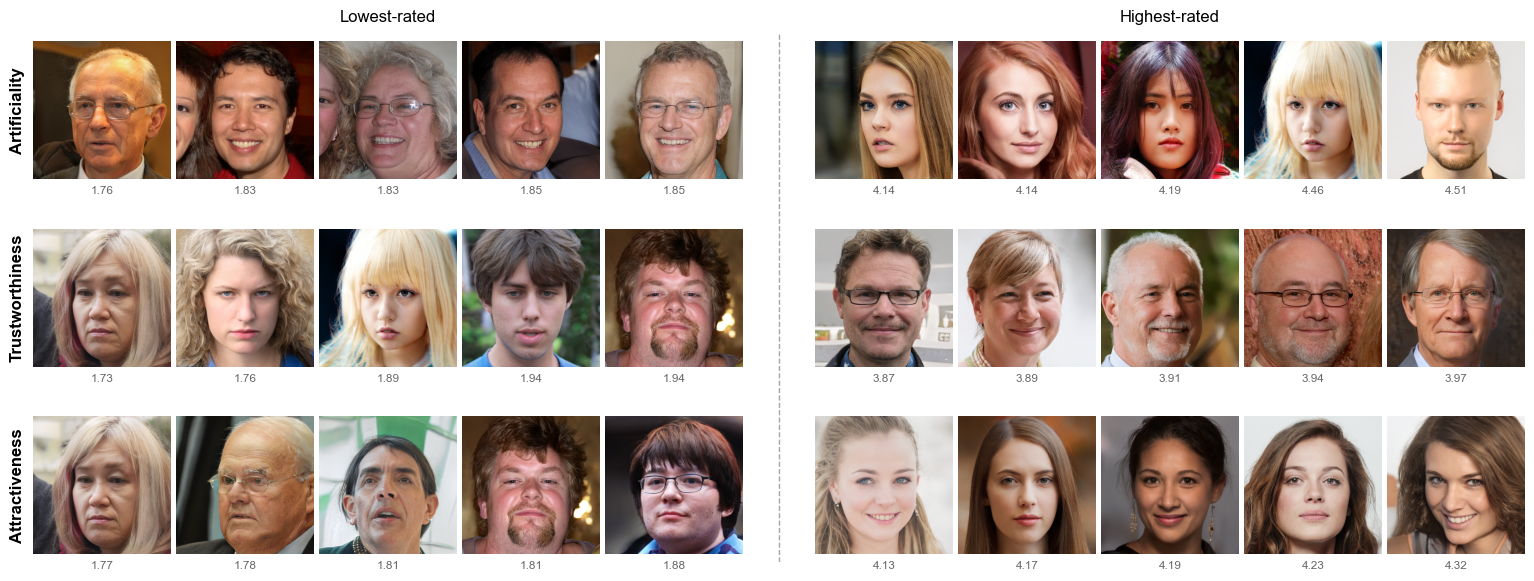

In [2]:
N_EXTREME = 5
records = []
for dim in DIMENSIONS:
    s = face_means[dim].sort_values()
    for sid, val in s.head(N_EXTREME).items():
        records.append(dict(dimension=dim, level='low', stimulus_id=sid, mean_rating=round(float(val), 3)))
    for sid, val in s.tail(N_EXTREME).items():
        records.append(dict(dimension=dim, level='high', stimulus_id=sid, mean_rating=round(float(val), 3)))
sel = pd.DataFrame(records)

nrows, spacer_idx = len(DIMENSIONS), N_EXTREME
ncols_total = 2 * N_EXTREME + 1
width_ratios = [1.0] * N_EXTREME + [0.45] + [1.0] * N_EXTREME
fig = plt.figure(figsize=(ncols_total * 1.45, nrows * 2.05))
gs = gridspec.GridSpec(nrows, ncols_total, figure=fig, width_ratios=width_ratios, wspace=0.04, hspace=0.22)
fig.subplots_adjust(left=0.055, right=0.99, top=0.91, bottom=0.05)
ax_div = fig.add_subplot(gs[:, spacer_idx]); ax_div.axis('off')
ax_div.set_xlim(0, 1); ax_div.set_ylim(0, 1); ax_div.axvline(0.5, color='0.65', lw=1.0, ls='--')
face_cols = list(range(N_EXTREME)) + list(range(N_EXTREME + 1, ncols_total))
for r, dim in enumerate(DIMENSIONS):
    sub = sel[sel['dimension'] == dim]
    low = sub[sub['level'] == 'low'].sort_values('mean_rating')
    high = sub[sub['level'] == 'high'].sort_values('mean_rating')
    ordered = pd.concat([low, high]).reset_index(drop=True)
    for k, cpos in enumerate(face_cols):
        ax = fig.add_subplot(gs[r, cpos]); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values(): sp.set_visible(False)
        rowdat = ordered.iloc[k]; path = find_image(rowdat['stimulus_id'])
        if path: ax.imshow(Image.open(path))
        else: ax.imshow(np.full((512, 512, 3), 0.85))
        ax.text(0.5, -0.05, '{:.2f}'.format(rowdat['mean_rating']), ha='center', va='top',
                fontsize=8.5, color='0.4', transform=ax.transAxes)
        if k == 0: ax.set_ylabel(dim, fontsize=12, fontweight='bold', labelpad=6)
        if r == 0 and k == N_EXTREME // 2: ax.set_title('Lowest-rated', fontsize=12, pad=14)
        if r == 0 and k == N_EXTREME + N_EXTREME // 2: ax.set_title('Highest-rated', fontsize=12, pad=14)
plt.show()

##Participant-wise Spearman's rho distributions

Each participant's three zero-order Spearman correlations. The red line is the group-mean rho (Fisher-z averaged) and the shaded band its 95% confidence interval; the black line marks rho = 0.

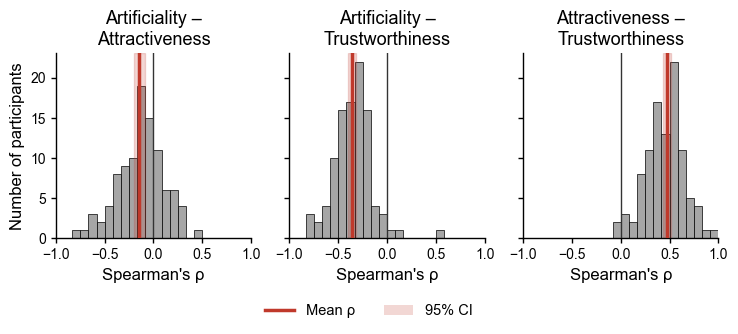

In [3]:
fig = mf.figure_zero_order(corr)
plt.show()

## Joint distribution of participant-wise partial correlations

Each grey point is one participant: x = partial rho(artificiality, attractiveness | trustworthiness); y = partial rho(artificiality, trustworthiness | attractiveness). Marginal histograms, dotted zero lines, and the dashed identity line (y = x).

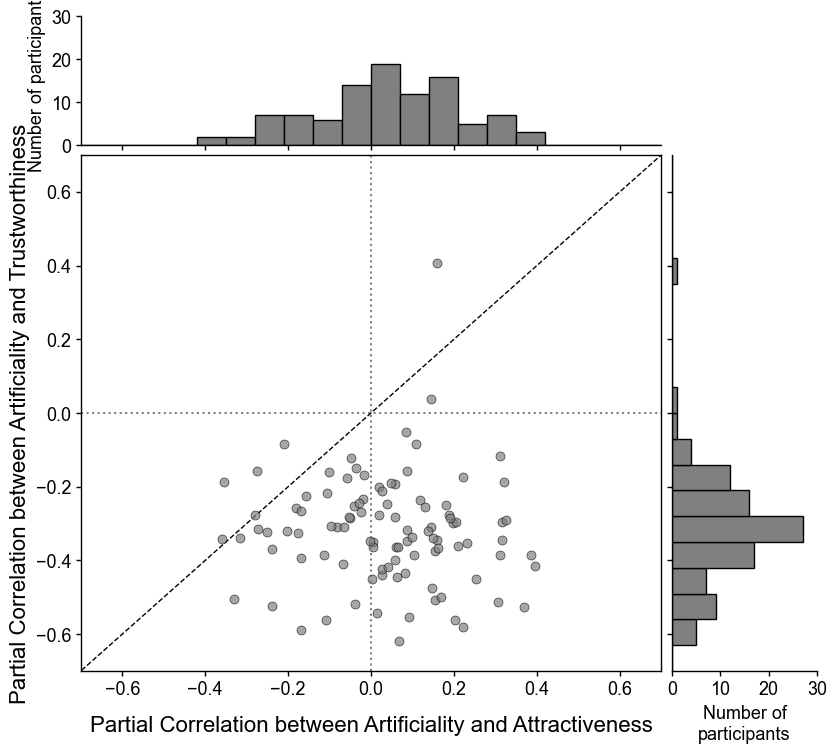

In [4]:
fig = mf.figure_partial_joint(partial)
plt.show()

## GEE marginal predictions with observed means

Population-averaged GEE predictions of attractiveness (A) and trustworthiness (B) across the artificiality scale, each holding the other rating at its sample mean, with 95% confidence bands and the observed per-level mean ratings (+/- 95% CI) overlaid. Both panels share a common y-axis.

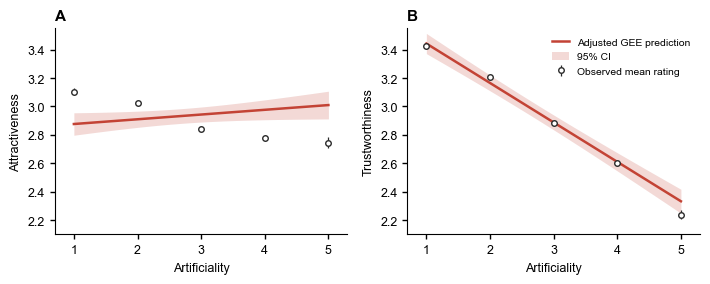

In [5]:
fig = mf.figure_gee_predictions(trials)
plt.show()

## Low- and high-perceived-artificiality example faces

The five lowest- and five highest-perceived-artificiality faces, each labelled with its mean artificiality, trustworthiness, and attractiveness.

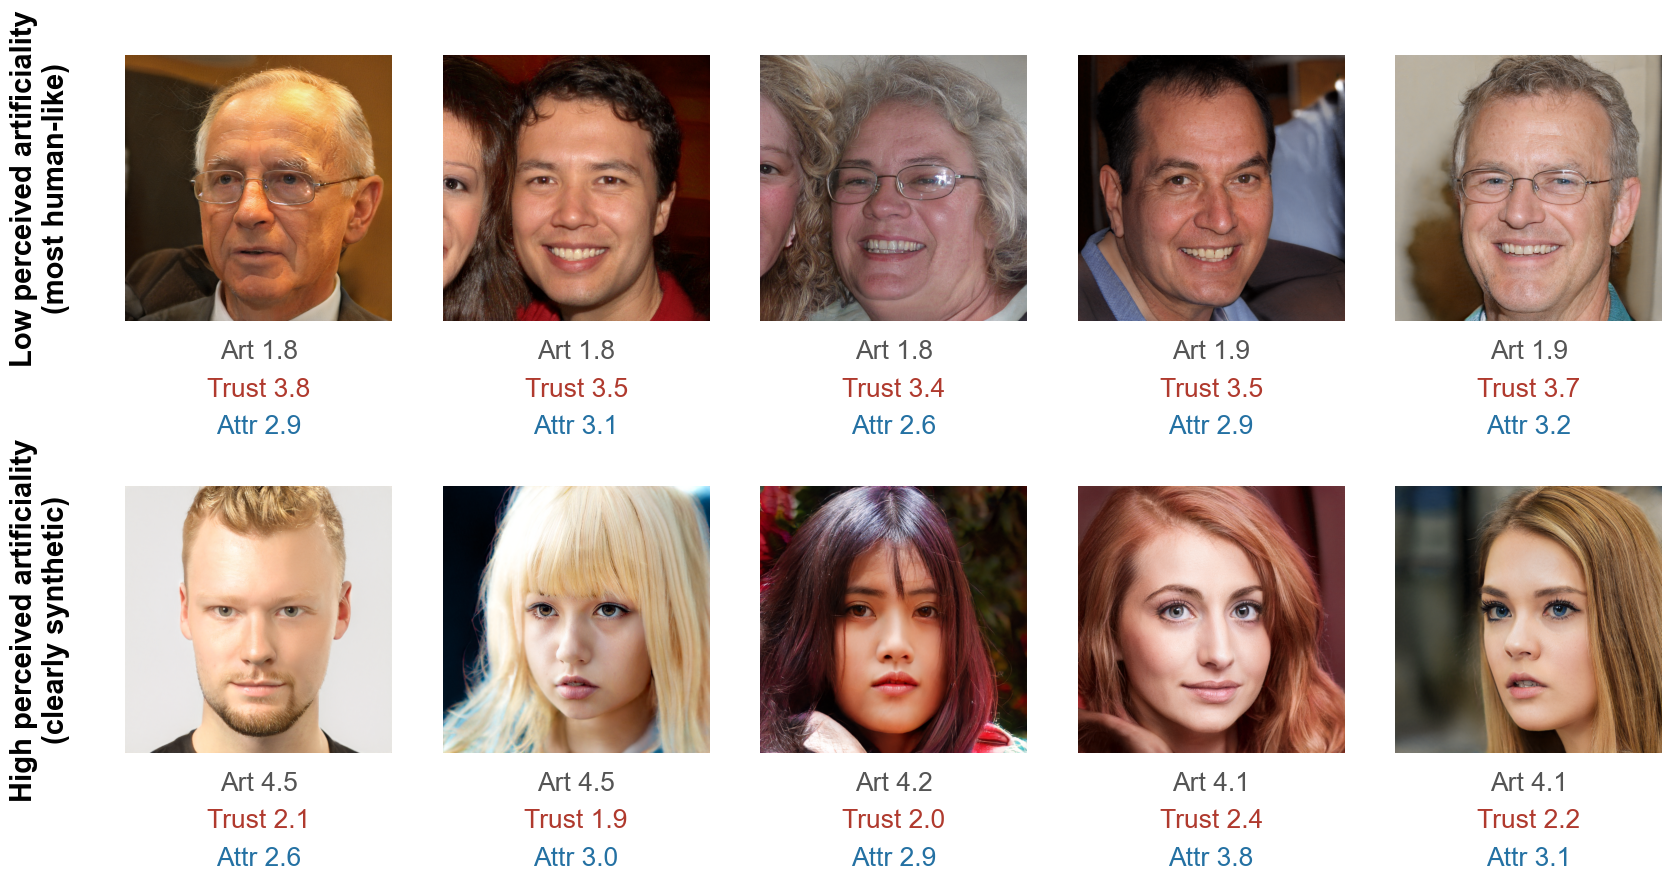

In [6]:
low = face_means['Artificiality'].sort_values().head(5)
high = face_means['Artificiality'].sort_values(ascending=False).head(5)
ART_C, TR_C, AT_C = '#555555', '#b03a2e', '#2471a3'
ROW_FS, MAIN, SIDE = 21, 19, 19
fig = plt.figure(figsize=(17, 7.8))
gs = fig.add_gridspec(2, 5, left=0.075, right=0.995, top=0.955, bottom=0.06, wspace=0.08, hspace=0.62)
panel_rows = [('Low perceived artificiality\n(most human-like)', list(low.index)),
              ('High perceived artificiality\n(clearly synthetic)', list(high.index))]
axref = {}
for r, (label, sids) in enumerate(panel_rows):
    for c in range(5):
        sid = sids[c]
        ax = fig.add_subplot(gs[r, c]); ax.set_box_aspect(1); ax.axis('off')
        ax.imshow(Image.open(find_image(sid)))
        ax.text(0.5, -0.07, 'Art %.1f' % face_means.loc[sid, 'Artificiality'], transform=ax.transAxes,
                ha='center', va='top', fontsize=SIDE, color=ART_C)
        ax.text(0.5, -0.21, 'Trust %.1f' % face_means.loc[sid, 'Trustworthiness'], transform=ax.transAxes,
                ha='center', va='top', fontsize=MAIN, color=TR_C)
        ax.text(0.5, -0.35, 'Attr %.1f' % face_means.loc[sid, 'Attractiveness'], transform=ax.transAxes,
                ha='center', va='top', fontsize=SIDE, color=AT_C)
        axref[(r, c)] = ax
fig.canvas.draw()
for r, (label, sids) in enumerate(panel_rows):
    p = axref[(r, 0)].get_position()
    fig.text(0.033, p.y0 + p.height / 2, label, rotation=90, va='center', ha='center',
             fontsize=ROW_FS, fontweight='bold')
plt.show()

## Non-linearity (uncanny-valley) trends

Stimulus-level mean ratings against mean perceived artificiality, with linear and quadratic fits and quintile means (+/- SE), in the house style. No uncanny-valley dip. Test statistics are in `docs/NONLINEARITY_ANALYSIS.md`.

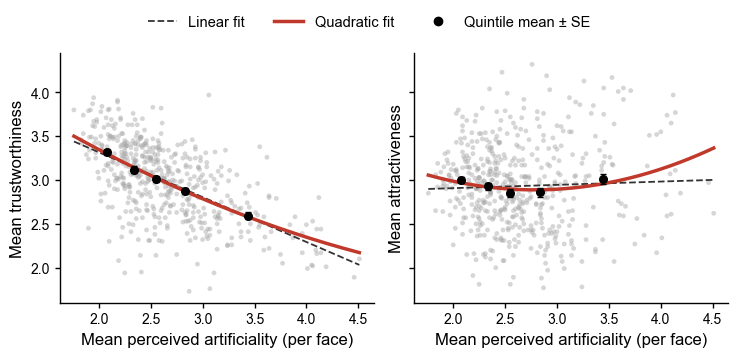

In [7]:
fig = mf.figure_nonlinearity(face_means)
plt.show()

## Facial expression (AU12) versus ratings

Per-face smile intensity (AU12) against the three per-face mean ratings. Smile intensity relates to trustworthiness and attractiveness but is essentially unrelated to perceived artificiality.

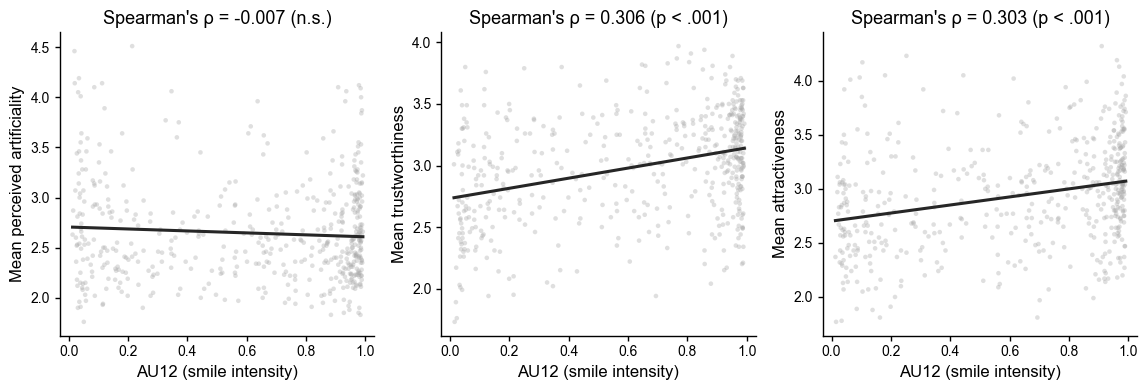

In [8]:
fig = mf.figure_au12_vs_ratings(face_means, features)
plt.show()

## Per-participant expression robustness

For each pairwise partial correlation, every participant's estimate before (x) and after (y) adding AU12 as a covariate. Points sit on the identity line and the Fisher-z pooled estimate (red diamond) is essentially unchanged.

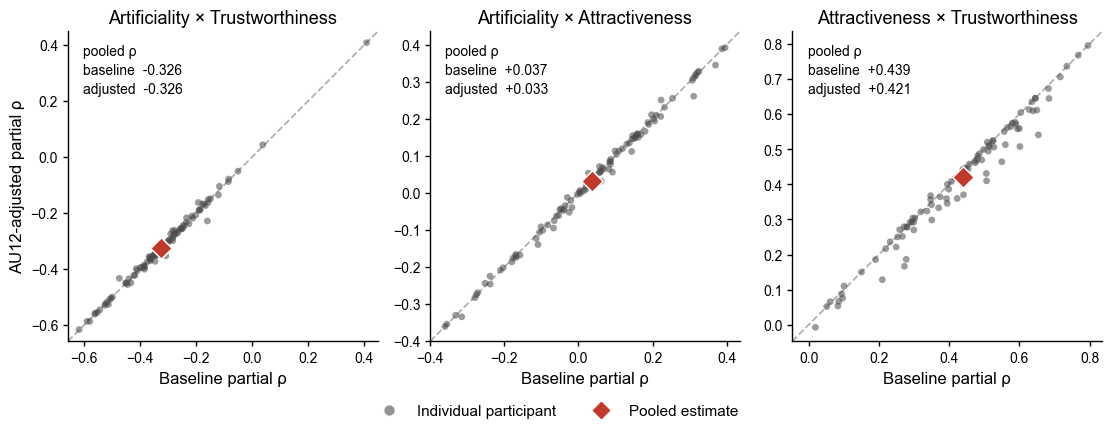

In [9]:
au12 = features[['stimulus_id', 'AU12']]
fig = mf.figure_expression_robustness(trials, au12)
plt.show()